In [22]:
import pandas as pd
import numpy as np
import os
import sys
sys.path.append(os.path.abspath(".."))
from src.config import TRADING_DAYS
from src.returns import describe_returns, prices_wide,bank_index,normality_test,log_returns,simple_returns,rolling_volatility
from src.build_dataset import build_dataset
from src.plots import plot_return_hist,plot_qq,plot_rolling_vol
from pathlib import Path

## Loading datasets

In [3]:
stocks, currency = build_dataset()
stocks_wide_df = prices_wide(stocks)
stocks_wide_df_log_returns = log_returns(stocks_wide_df)
stocks_index = np.log(1 + bank_index(simple_returns(stocks_wide_df)))

## Describing returns

In [5]:
describe_returns(stocks_wide_df_log_returns)

,n_days,mean,std,std_annual,skew,excess_kurtosis,min,max
ticker,,,,,,,,
Alior,2958,0.000362,0.025483,0.404527,-0.280862,6.834024,-0.221643,0.164658
ING,2962,0.000539,0.019620,0.311461,0.137360,3.954093,-0.116339,0.124162
Millennium,2962,0.000340,0.026660,0.423213,-0.347812,6.903975,-0.240397,0.166729
PKO BP,2962,0.000514,0.020393,0.323730,-0.316262,5.613795,-0.184174,0.124590
Pekao,2962,0.000382,0.020659,0.327954,-0.488095,9.469412,-0.218040,0.158164
mBank,2930,0.000394,0.025465,0.404242,0.256950,5.381664,-0.178323,0.215841


## Plotting returns for index and PKO BP

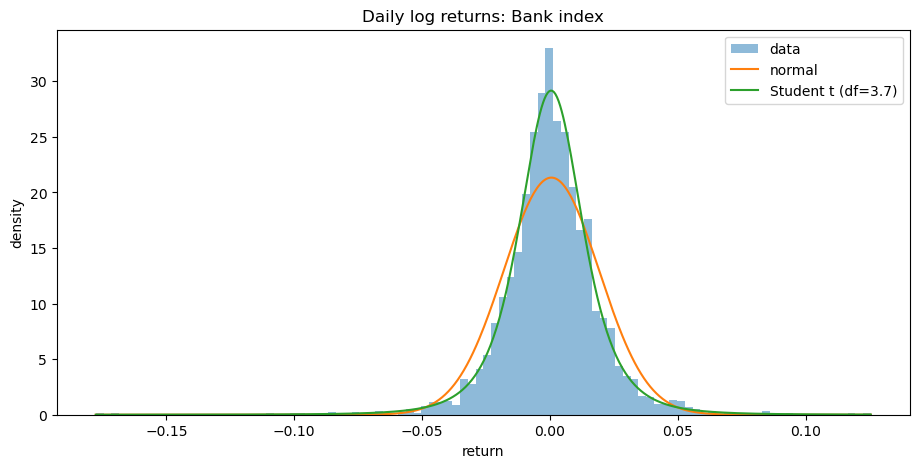

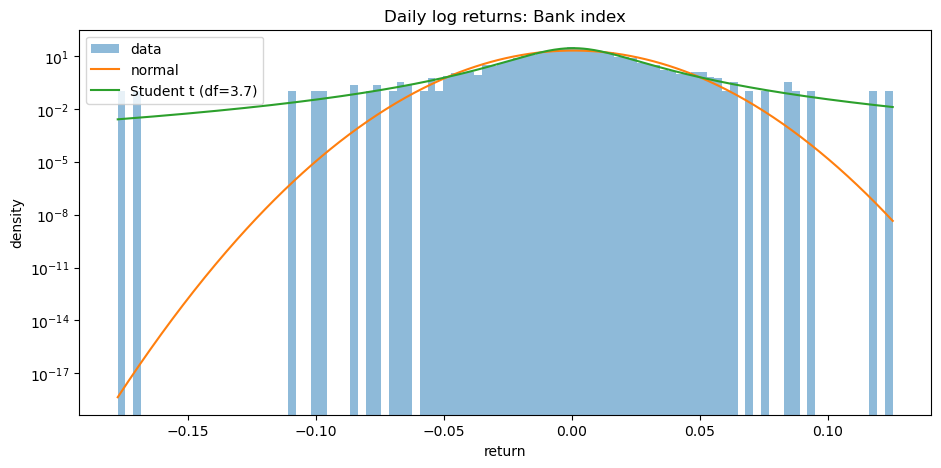

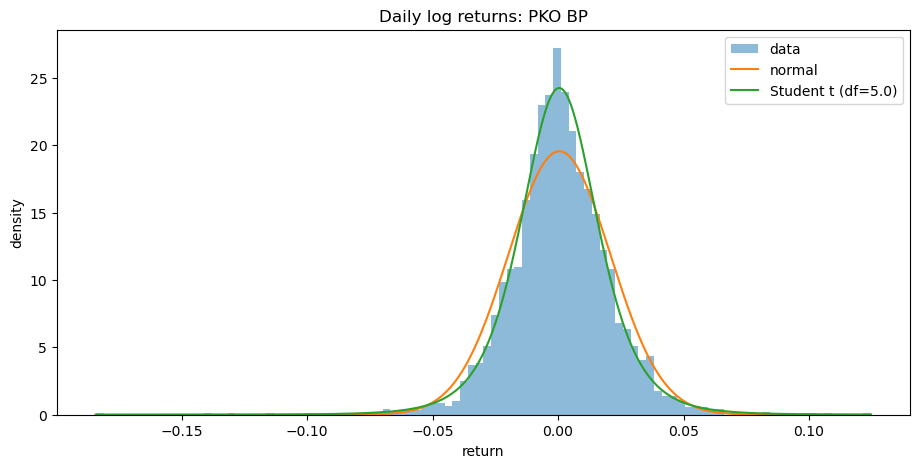

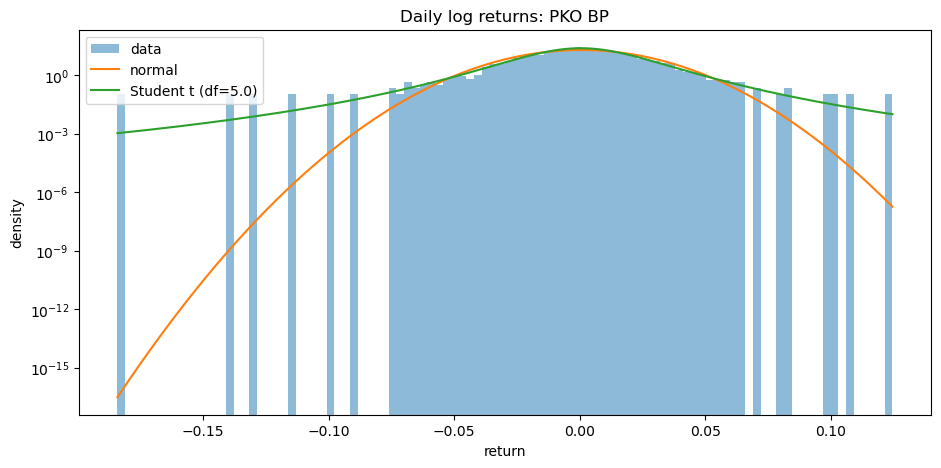

In [7]:
index_plot = plot_return_hist(stocks_index)
index_plot_log_scale = plot_return_hist(stocks_index,True)
pko_bp_plot = plot_return_hist(stocks_wide_df_log_returns["PKO BP"])
pko_bp_plot_log_scale = plot_return_hist(stocks_wide_df_log_returns["PKO BP"],True)

## QQ for index and PKO BP

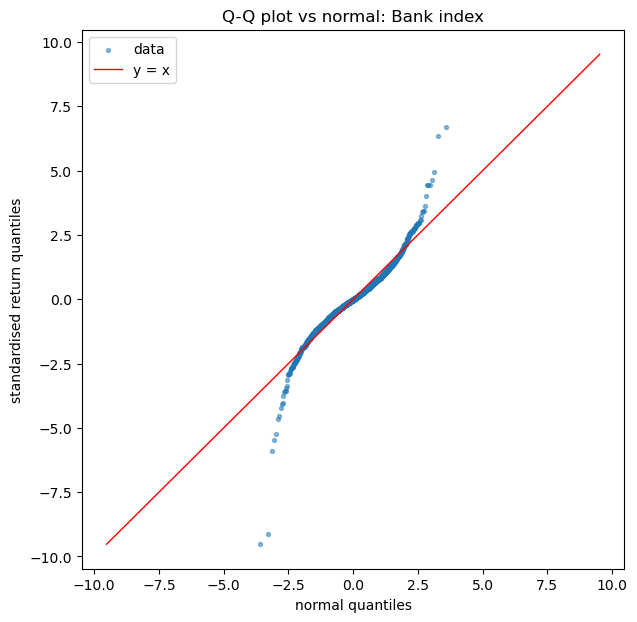

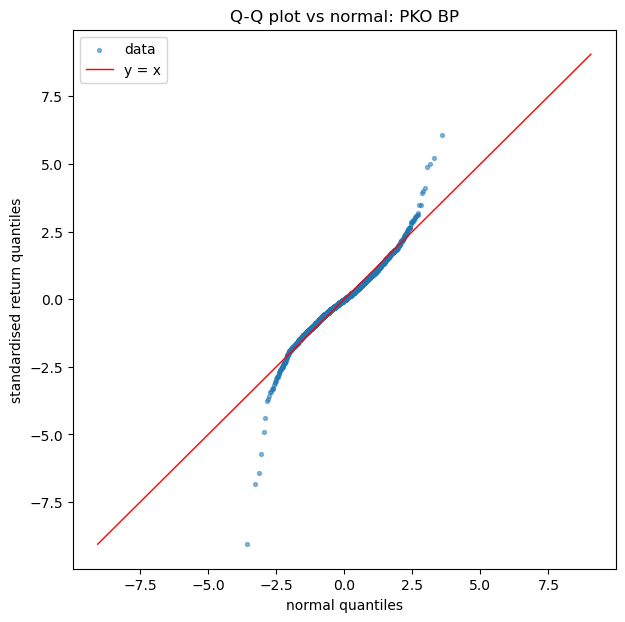

In [9]:
index_qq = plot_qq(stocks_index)
pko_bp_qq = plot_qq(stocks_wide_df_log_returns["PKO BP"])

## Normality test for each bank

In [11]:
normality_test(stocks_wide_df_log_returns)

,jb_stat,p_value,reject_normality
Alior,5772.260773,0.0,True
ING,1930.427762,0.0,True
Millennium,5919.020794,0.0,True
PKO BP,3922.850793,0.0,True
Pekao,11142.196415,0.0,True
mBank,3553.286729,0.0,True


## Plotting rolling volatility

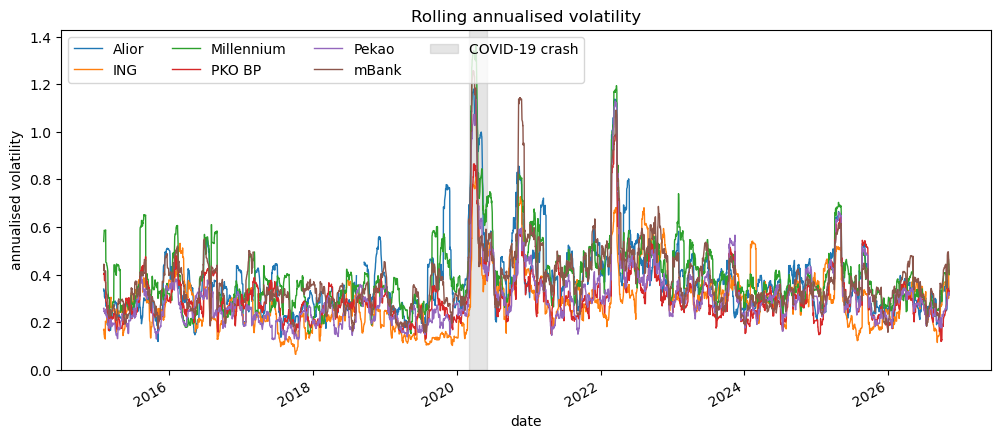

In [13]:
vol = rolling_volatility(stocks_wide_df_log_returns)
roll_vol = plot_rolling_vol(vol)

ax = roll_vol.axes[0]
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2020-05-31"), color="grey", alpha=0.2, label="COVID-19 crash")
ax.legend(loc="upper left", ncol=4)

In [24]:
images_dir = Path("../images")
images_dir.mkdir(exist_ok=True)

index_plot_log_scale.savefig(images_dir / "index_hist_log.png", dpi=150, bbox_inches="tight")
roll_vol.savefig(images_dir / "rolling_vol.png", dpi=150, bbox_inches="tight")